# A pretrained MobileNetV2: full and selected CIM conversion
Load torchvision's ImageNet model directly, evaluate it, then compare all-layer CIM with CIM that keeps the first convolution and final classifier digital. Supply the ImageNet validation directory through `MEMFAST_IMAGENET_ROOT`. Run cells in order after installing MemFast. Pretrained weights use torchvision's upstream download/cache.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models

from memfast import Config, Nonidealities, Simulator, convert_model

torch.manual_seed(135)
torch.set_num_threads(4)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
data_root = Path(os.environ.get("MEMFAST_IMAGENET_ROOT", "data/imagenet/val"))
max_samples = None  # Full validation split; set an integer for an explicit subset.
batch_size = 64
workers = 4
baseline = dict(
    activation_bits=8,
    weight_bits=8,
    array_size=(64, 64),
    input_slice=(1,) * 8,
    weight_slice=(1,) * 8,
)
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights).to(device).eval()
print("Pretrained model:", type(model).__name__, "device:", device)
print("CIM baseline:", baseline)

Pretrained model: MobileNetV2 device: cuda:0
CIM baseline: {'activation_bits': 8, 'weight_bits': 8, 'array_size': (64, 64), 'input_slice': (1, 1, 1, 1, 1, 1, 1, 1), 'weight_slice': (1, 1, 1, 1, 1, 1, 1, 1)}


## 1. Load the evaluation split with pretrained preprocessing
Class directories must follow ImageNet's standard 1,000-class index order.

In [2]:
dataset = datasets.ImageFolder(data_root, transform=weights.transforms())
if len(dataset.classes) != 1000:
    raise ValueError("Expected all 1,000 ImageNet class directories in standard order")
selected = (
    dataset if max_samples is None else Subset(dataset, range(min(max_samples, len(dataset))))
)
batches = DataLoader(
    selected,
    batch_size=batch_size,
    shuffle=False,
    num_workers=workers,
    pin_memory=device.type == "cuda",
    persistent_workers=workers > 0,
)
print("Validation images:", len(selected), "of", len(dataset), "batch size:", batch_size)


@torch.inference_mode()
def accuracy(network, label):
    correct = count = 0
    network.eval()
    for images, labels in batches:
        logits = network(images.to(device, non_blocking=True))
        assert torch.isfinite(logits).all()
        correct += int((logits.argmax(1).cpu() == labels).sum())
        count += labels.numel()
        if count <= 2 * batch_size or count % 1000 < labels.numel() or count == len(selected):
            print(
                f"{label}: {count:,}/{len(selected):,} images, top-1 {correct / count:.2%}",
                flush=True,
            )
    if count == 0:
        raise ValueError("No validation images found")
    assert count == len(selected)
    return correct / count, count


digital, count = accuracy(model, "Digital")
print(f"Digital top-1: {digital:.2%}, {count} images")

Validation images: 50000 of 50000 batch size: 64


Digital: 64/50,000 images, top-1 89.06%


Digital: 128/50,000 images, top-1 88.28%


Digital: 1,024/50,000 images, top-1 87.79%


Digital: 2,048/50,000 images, top-1 81.84%


...

Digital: 47,040/50,000 images, top-1 72.00%


Digital: 48,000/50,000 images, top-1 72.18%


Digital: 49,024/50,000 images, top-1 71.95%


Digital: 50,000/50,000 images, top-1 72.15%


Digital top-1: 72.15%, 50000 images


## 2. Convert every supported layer
Conv2d (including depthwise) and Linear become CIM layers. Batch normalization, activations, pooling and residual additions retain their PyTorch behavior. Only write variation is enabled at 0.02.

In [3]:
config = Config(**baseline, nonidealities=Nonidealities(write_variation=0.02), seed=135)
engine = Simulator(config, device=device)
analog = convert_model(model, engine)
print("Full conversion ready; evaluating", len(selected), "images", flush=True)
full_cim, full_count = accuracy(analog, "Full CIM")
assert full_count == count
print(f"Full CIM top-1: {full_cim:.2%}, {full_count} images")
del analog, engine

Full conversion ready; evaluating 50000 images


Full CIM: 64/50,000 images, top-1 89.06%


Full CIM: 128/50,000 images, top-1 86.72%


Full CIM: 1,024/50,000 images, top-1 87.40%


Full CIM: 2,048/50,000 images, top-1 81.69%


...

Full CIM: 47,040/50,000 images, top-1 71.75%


Full CIM: 48,000/50,000 images, top-1 71.93%


Full CIM: 49,024/50,000 images, top-1 71.69%


Full CIM: 50,000/50,000 images, top-1 71.88%


Full CIM top-1: 71.88%, 50000 images


## 3. Keep the first convolution and classification head digital
Inspect module names, then pass exclusions directly. Each conversion starts from the same pretrained digital model.

First: ('features.0.0', 'Conv2d') last: ('classifier.1', 'Linear')


Partial conversion ready; evaluating 50000 images


First/head digital: 64/50,000 images, top-1 89.06%


First/head digital: 128/50,000 images, top-1 87.50%


First/head digital: 1,024/50,000 images, top-1 87.40%


...

First/head digital: 47,040/50,000 images, top-1 71.74%


First/head digital: 48,000/50,000 images, top-1 71.91%


First/head digital: 49,024/50,000 images, top-1 71.68%


First/head digital: 50,000/50,000 images, top-1 71.88%


Partial CIM top-1: 71.88%, 50000 images


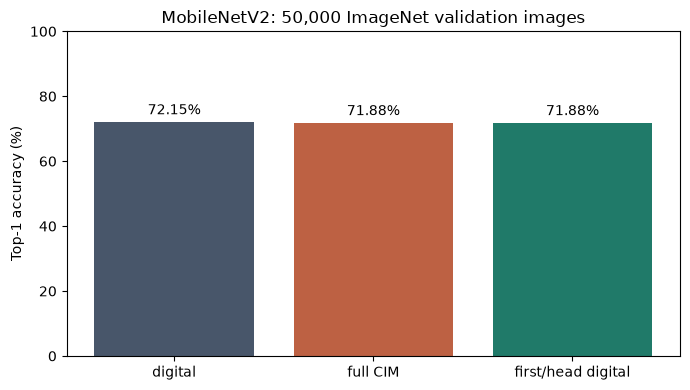

{'digital': 0.7215, 'full CIM': 0.71882, 'first/head digital': 0.7188}

In [4]:
eligible = [
    (name, type(layer).__name__)
    for name, layer in model.named_modules()
    if isinstance(layer, (nn.Conv2d, nn.Linear))
]
print("First:", eligible[0], "last:", eligible[-1])
first_layer = eligible[0][0]
head = "classifier"
engine = Simulator(config, device=device)
partial = convert_model(model, engine, exclude=(first_layer, head))
print("Partial conversion ready; evaluating", len(selected), "images", flush=True)
assert isinstance(partial.get_submodule(first_layer), nn.Conv2d)
assert isinstance(partial.classifier[1], nn.Linear)
partial_cim, partial_count = accuracy(partial, "First/head digital")
assert partial_count == count
print(f"Partial CIM top-1: {partial_cim:.2%}, {partial_count} images")
comparison = {"digital": digital, "full CIM": full_cim, "first/head digital": partial_cim}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    comparison.keys(),
    [100 * value for value in comparison.values()],
    color=["#48566a", "#bd6143", "#207a69"],
)
ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set(
    ylabel="Top-1 accuracy (%)",
    ylim=(0, 100),
    title=f"MobileNetV2: {count:,} ImageNet validation images",
)
fig.tight_layout()
plt.show()
comparison

Accuracy differences depend on checkpoint, dataset, quantization and device parameters. This comparison uses identical images and a fixed programming realization; no improvement from excluding layers is assumed. Use `include=(...)` to select only named layers instead.